In [1]:
# -*- coding: utf-8 -*-
#  Copyright 2021 United Kingdom Research and Innovation
#  Copyright 2021 The University of Manchester
#  Copyright 2021 The Karlsruhe Institute of Technology
#  Copyright 2021 Technical University of Denmark 
#
#  Licensed under the Apache License, Version 2.0 (the "License");
#  you may not use this file except in compliance with the License.
#  You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
#  Unless required by applicable law or agreed to in writing, software
#  distributed under the License is distributed on an "AS IS" BASIS,
#  WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
#  See the License for the specific language governing permissions and
#  limitations under the License.
#
#   Authored by:    Laura Murgatroyd (UKRI-STFC)
#                   Margaret Duff (UKRI-STFC)
#                   Evelina Ametova (KIT)
#                   Jakob S. Jørgensen (DTU)
#                   Gemma Fardell (UKRI-STFC)
#                   Edoardo Pasca (UKRI-STFC)
#                   Hannah Robarts (UKRI-STFC)

# Introduction to SIRT

**The goal** of this notebook is to get familiar with the CIL `Algorithm` and `Operator` classes, and be able to use the Simultaneous Image Reconstruction Technique (SIRT).

It works with a 2D slice of an IMAT dataset.

**Learning objectives**

In the end of this session, participants will be able to:
- formulate CT reconstruction as an optimisation problem and solve it iteratively using SIRT
- introduce non-negativity constraints in the optimisation problem
- visualise final and intermediate reconstruction results

In [2]:
# cil imports
from cil.processors import Slicer

from cil.optimisation.functions import IndicatorBox
from cil.optimisation.algorithms import SIRT
from cil.optimisation.utilities import callbacks

from cil.plugins.astra.operators import ProjectionOperator

from cil.recon import FBP

from cil.utilities.display import show2D, show1D

# External imports
import numpy as np
import matplotlib.pyplot as plt
import logging
from skimage.metrics import structural_similarity as ssim

from data_io.alum_cyl_io import read_processed_data
from utils.masks import create_circular_mask
from utils.metrics import calculate_L2Norm_error
from cil.optimisation.utilities import callbacks


/home/laura/miniconda3/envs/cil_demos_26/lib/python3.12/site-packages/cil/processors/CofR_image_sharpness.py:21: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  import scipy


In [3]:
# Set logging level for CIL processors:
logging.basicConfig(level=logging.WARNING)
cil_log_level = logging.getLogger('cil.processors')
cil_log_level.setLevel(logging.INFO)

In [4]:
# set up default colour map for visualisation
cmap = "inferno"

In [5]:
# set the backend for FBP and the ProjectionOperator
device = 'gpu'

This notebook works with the Aluminium Cylinder Flexible Neutron Tomography Dataset.
This is available on zenodo at: https://zenodo.org/records/19387166

Specifically, these notebooks work with the pre-processed data, for which the direct download link is: https://zenodo.org/records/19387166/files/preprocessed_data.zip?download=1

You will need to update the `processed_data_path` variable in data_io/alum_cyl_file_paths.py to point to this (unzipped) folder.

In [6]:
full_data_slice = read_processed_data(exposure_time=60, num_angles=840, vertical=987) 
reduced_data_slice = read_processed_data(exposure_time=30, num_angles=210, vertical=987) 

INFO:cil.processors.TransmissionAbsorptionConverter:
 Current min_intensity = 0.0: output may contain NaN or inf. Ensure your data only contains positive values or set min_intensity to a small positive value.
INFO:cil.processors.TransmissionAbsorptionConverter:
 Current min_intensity = 0.0: output may contain NaN or inf. Ensure your data only contains positive values or set min_intensity to a small positive value.


In this notebook we will use data from a scan of the aluminium cylinder, comparing a full dataset (840 projections and 60s exposure) with a reduced dataset (210 projections, 30s exposure). The reduced data has 1/8 of the total exposure time of the full data.

We start with data which was already pre-processed in Mantid Imaging. For information on the sample, see Angles_vs_Exposure_01_Introduction_to_Aluminium_Cylinder.ipynb.

## CT reconstruction
Tomographic reconstruction consists of resolving the three-dimensional photon attenuation map of a scanned object from the collection of projection measurement. There are two major classes of reconstruction algorithms: *analytic* and *iterative*. 

### FBP

The FBP algorithm is implemented as a `Processor` which is set up with an `AcquisitionGeometry` and an `ImageGeometry`. You then can call your configured FBP processor  on an `AcquisitionData` object. The processor returns the reconstructed `ImageData`.

In [7]:
image_geometry = full_data_slice.geometry.get_ImageGeometry()

# reconstruct full and reduced data with FBP
recon_fbp_full = FBP(full_data_slice, image_geometry).run()
recon_fbp_reduced = FBP(reduced_data_slice, image_geometry).run()

FBP recon

Input Data:
	angle: 840
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):

FBP recon

Input Data:
	angle: 210
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):



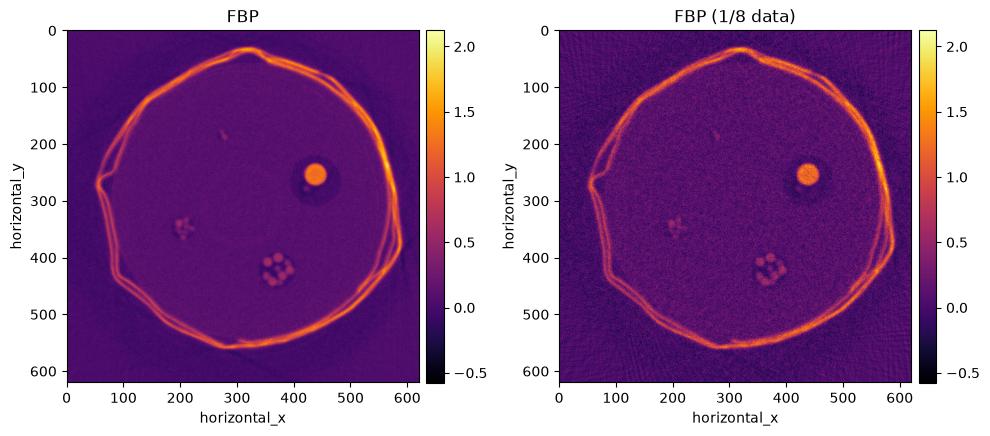

In [8]:
range_min = min(recon_fbp_full.as_array().min(), recon_fbp_reduced.as_array().min())
range_max = max(recon_fbp_full.as_array().max(), recon_fbp_reduced.as_array().max())

show2D([recon_fbp_full, recon_fbp_reduced], ['FBP', 'FBP (1/8 data)'], cmap=cmap, num_cols=2, size=(10,10), origin='upper-left', fix_range=(range_min, range_max))

We know that outside the cylinder is just air so we can use a circular mask to remove some noise in the background. Then when we are comparing the reconstructions the results won't be skewed by the background.

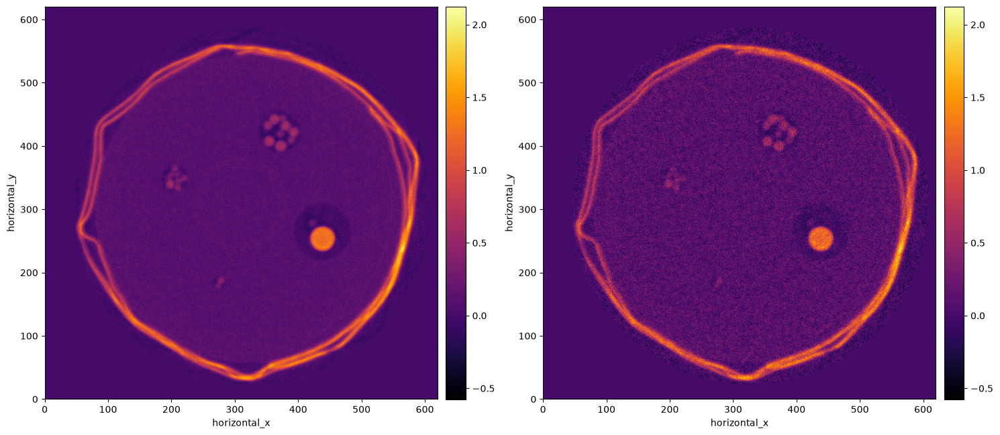

In [9]:
# circular mask applied to reconstructions: centre in pixels (row, col) and radius as a fraction of the half-size
MASK_CENTRE_PX = [305, 327]
MASK_RADIUS = 0.91


masked_fbp_full = create_circular_mask(recon_fbp_full, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
masked_fbp_reduced = create_circular_mask(recon_fbp_reduced, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
show2D([masked_fbp_full, masked_fbp_reduced], cmap=cmap, fix_range=True)

### Iterative reconstruction
Iterative methods use an initial estimate of volume voxel values which is then iteratively updated to best reproduce acquired radiographic data. Here we discuss formulation of iterative reconstruction for 2D parallel geometry, extension to other geometries is straightforward. Iterative methods formulate the reconstruction methods as a system of linear equations,

$$Au = b$$

- $u$ is the volume to be reconstructed. $u$ is typically represented as a column vector with $N \cdot N \times 1$ elements, where $N$ is the number of elements in a detector row.
- $b$ is measured data from $M$ measurements (projections), $b$ is a column vector with $N \cdot M \times 1$ elements
- $A$ is the projection operator with $N \cdot M \times N \cdot N$ elements. If $i, i = \{0, 1, \dots N \cdot M - 1 \}$ and $j, j = \{0, 1, \dots, N \cdot N - 1\}$, then $A_{i,j}$ is the length of intersection of the $i$.th ray with the $j$.th voxel.

For any real application, the problem size is too large to be solved by direct inversion methods, i.e.

$$u = A^{-1}b$$

Secondly, the projection matrix $A$ is often under-determined (low number of projections or missing angles), i.e. 

$$M \ll N$$

Therefore we formulate reconstruction as an optimisation problem and use iterative solvers to solve:

$$\underset{u}{\mathrm{argmin}}\begin{Vmatrix}A u - b\end{Vmatrix}^2_2$$

Since iterative methods involve forward- and back-projection steps, assumptions of data acquisition, data processing, system geometries, and noise characteristic can be incorporated into the reconstruction procedure. However, iterative methods are computationally demanding, you will notice that it takes longer to get reconstruction results with iterative methods.

From mathematical point of view, projection matrix $A$ is an operator which maps from the set $x$ (*domain*) to the set $b$ (*range*):
$$A: u \to b$$
In the framework, we implemented a generic `Operator` class. The two most important methods of the `Operator` are `direct` and `adjoint` methods that describe the result of applying the operator, and its adjoint respectively, onto a compatible `DataContainer` (`AcquisitionData` or `ImageData`) input. The output is another `DataContainer` object or subclass hereof. An important special case of the `Operator` class, is the projection operator $A$ for CT, where `direct` and `adjoint` method correspond to forward- and back-projection respectively. 

In [10]:
A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

The Framework provides a number of generic optimisation algorithms implementations. All algorithms share the same interface and behaviour. Algorithms are iterable Python objects which can be run in a for loop, can be stopped and warm restarted.


### Iterative reconstruction with SIRT

The SIRT (Simultaneous Iterative Reconstruction Technique) algorithm, is an algebraic iterative method for a particular weighted least-squares problem which in addition optionally accepts certain convex constraints such as a non-negativity constraint.

SIRT takes our Projection `operator`, measured data and initial value as an input. 


#### Unconstrained SIRT Reconstruction

First, we run it unconstrained

In [11]:
# initial estimate - zero array in this case 
initial = image_geometry.allocate(0)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 10

/home/laura/miniconda3/envs/cil_demos_26/lib/python3.12/site-packages/cil/framework/data_container.py:495: RuntimeWarning: divide by zero encountered in power
  out = pwop(self.as_array(), self.dtype.type(x2), *args, **kwargs)


Now we need to run some iterations of the algorithm. This is done via the method `run`. You can specify how many iterations you want to run and the callback to use to show the state of the algorithm. Here we use the CIL TextProgressCallback to print out information every update_objective_interval so you can more clearly see what is happening. For more information on callbacks see https://tomographicimaging.github.io/CIL/nightly/optimisation/#callbacks

**Try to run the following cell and then re-run it. What happens?**

In [12]:
# run N interations
sirt.run(50, callbacks=[callbacks.TextProgressCallback()])

     0/50         ?it/s


    10/50     55.45it/s, objective=+9.198e+01
    20/50     56.43it/s, objective=+5.278e+01
    30/50     55.68it/s, objective=+3.992e+01
    40/50     54.08it/s, objective=+3.399e+01
    50/50     53.24it/s, objective=+3.075e+01
    50/50     54.06it/s



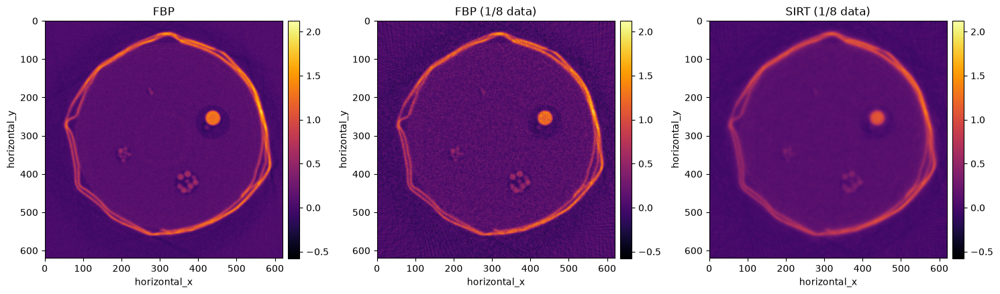

In [13]:
# get and visualise the results
recon_sirt = sirt.solution

show2D([recon_fbp_full, recon_fbp_reduced, recon_sirt], ['FBP', 'FBP (1/8 data)', 'SIRT (1/8 data)'], \
       cmap=cmap, num_cols=3, size=(15,10), origin='upper-left', fix_range=(range_min, range_max))

We can check if the algorithm converges:

If we plot the algorithm objective value as a function of the iteration number we can see the change in objective at each iteration becomes gradually smaller, until there is very little change between subsequent iterations which suggests the algorithm has converged

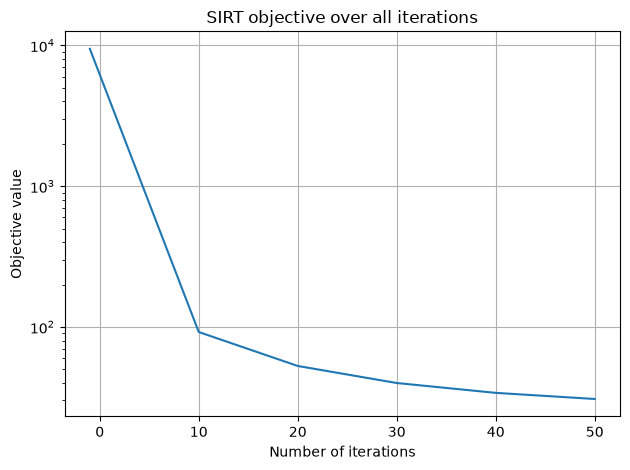

In [14]:
plt.plot(sirt.iterations, sirt.objective)
plt.yscale('log')
plt.xlabel('Number of iterations')
plt.ylabel('Objective value')
plt.title('SIRT objective over all iterations')
plt.grid(True)

plt.tight_layout()
plt.show()

## When to stop iterating?

The reconstruction above doesn't look particularly good. The number of iterations plays the role of a regularisation parameter. However, it is often unclear how many iterations is required to get 'good' reconstruction. To control how the reconstruction result changes with every iteration, we will visualise intermediate reconstruction results.

In [15]:
initial = image_geometry.allocate(0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 1

Let's run the algorithm, and check its progress to the solution after every iteration.

We create a custom callback which will plot the current solution, the difference with the full FBP, and the difference with the previous iteration.

We will also show the L2 Norm Error compared to the full FBP.

##### L2Norm Error (L2N-E)
This metric assesses the difference in pixel values between a reconstruction and the full FBP.
&nbsp;

Method:
&nbsp;

$$
\text{L2N-E} = \frac{\| \text{Recon} - \text{full FBP} \|_2}{\| \text{full FBP} \|_2}
$$
&nbsp;



In [16]:
class DifferenceImageCallback(callbacks.Callback):
    def __init__(self, target_image, initial, display_interval=50, fix_range=None, cmap="inferno"):
        self.target_image = create_circular_mask(target_image, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
        self.l2nes = []
        self.display_interval = display_interval
        self.previous_solution = initial
        self.fix_range = fix_range
        self.cmap = cmap

    def __call__(self, algorithm):
        algo_solution = create_circular_mask(algorithm.solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False) 

        l2_error = calculate_L2Norm_error(self.target_image, algo_solution)
        self.l2nes.append(l2_error)

        if algorithm.iteration % self.display_interval == 0:
            diff_from_full_fbp = algo_solution - self.target_image

            show2D([algo_solution, diff_from_full_fbp, algo_solution - self.previous_solution], 
                   ["Iteration {}, objective {:.2f}".format(algorithm.iteration, algorithm.loss[-1]),
                    "Difference from full FBP, L2NE: {:.4f}".format(l2_error),
                    "Difference with previous step"], fix_range= self.fix_range, 
                   cmap=self.cmap, num_cols=3, size=(15,10), origin='upper-left')
        
        self.previous_solution = algo_solution.copy()

Here we show running SIRT with this custom callback:

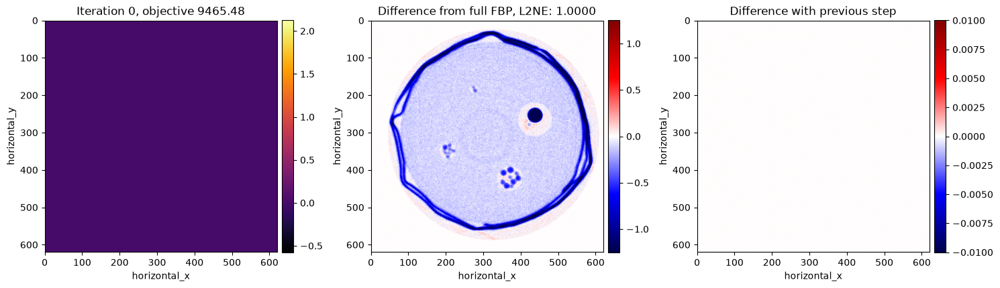

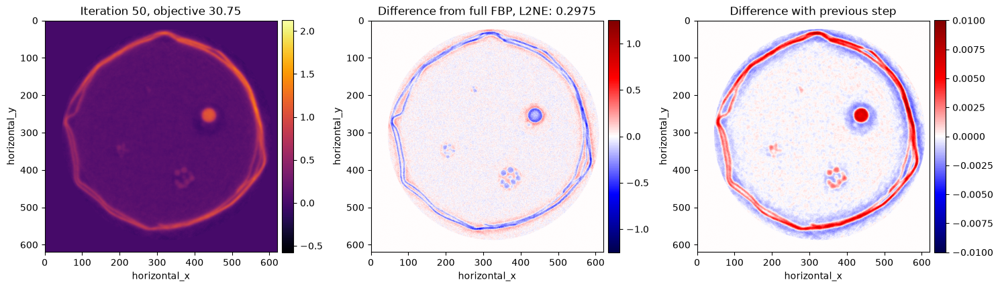

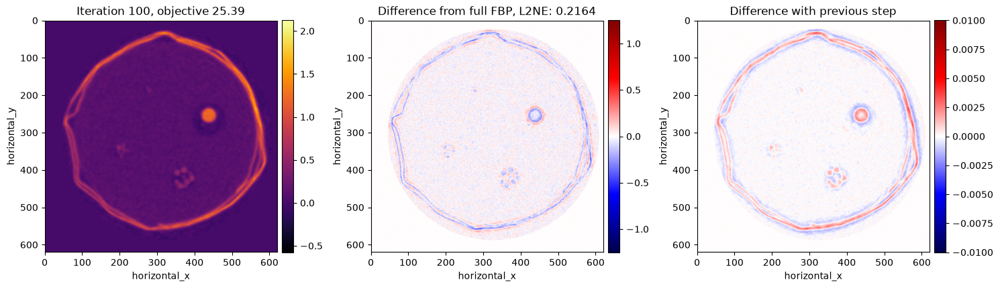

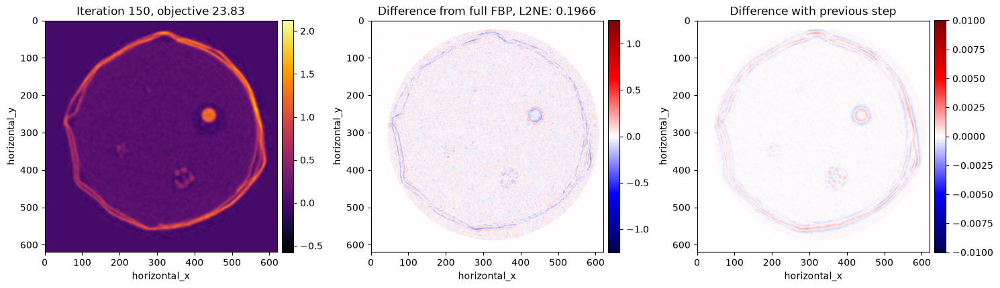

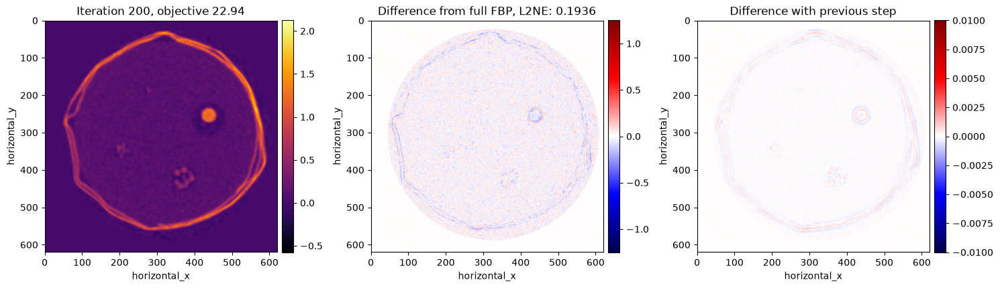

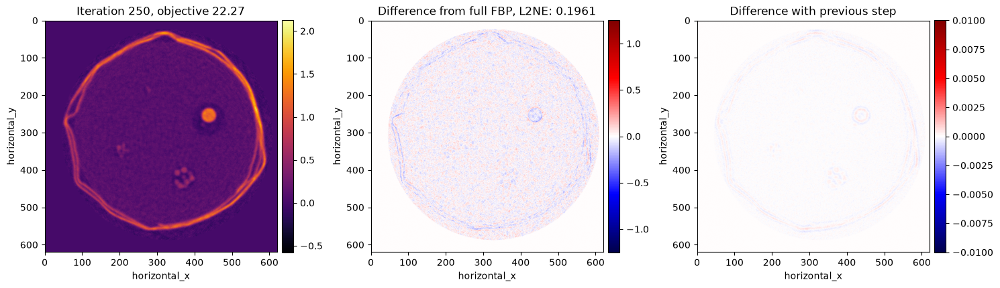

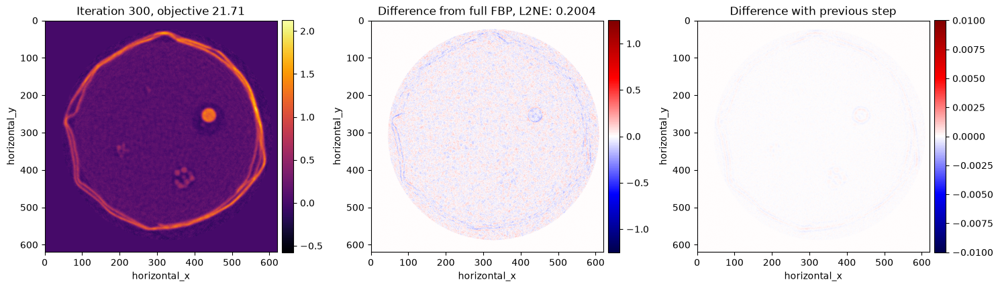

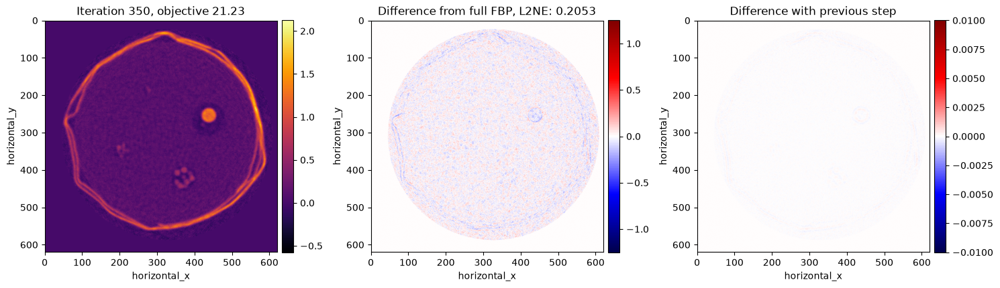

In [17]:
cb = DifferenceImageCallback(target_image=masked_fbp_full, initial=initial, display_interval=50, fix_range=[(range_min, range_max), (-1.25, 1.25), (-0.01, 0.01)], cmap=[cmap, 'seismic', 'seismic'])
sirt.run(350, callbacks=[cb])

We see as we continue to iterate, the difference with the previous iteration continues to get smaller and smaller. However, after iteration 200 the difference with the Full FBP reconstruction stops decreasing and begins increasing!

We can plot both the objective value and the L2Norm Error between the SIRT solution and the full FBP reconstruction, against iteration number, to visualise graphically what's happening:

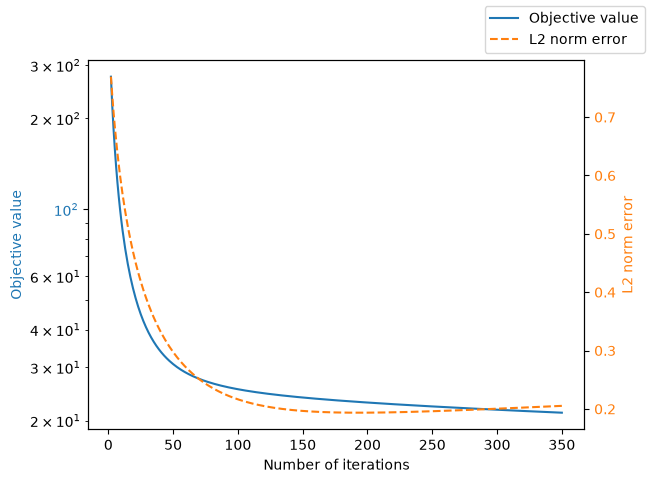

In [18]:
fig, ax1 = plt.subplots()

ax1.plot(sirt.iterations[2:], sirt.loss[2:], color='tab:blue')
ax1.set_yscale('log')
ax1.set_xlabel('Number of iterations')
ax1.set_ylabel('Objective value', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(sirt.iterations[2:], cb.l2nes[2:], '--', color='tab:orange') 
ax2.set_ylabel('L2 norm error', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')


fig.legend(['Objective value', 'L2 norm error'])
plt.show()


SIRT exhibits semi-convergence, meaning that it approaches the ground truth up to a point and then further iterations cause the solution to become more noisy, diverging from the ground truth. This means the number of iterations plays the role of a regularisation parameter, and we can't use convergence of the algorithm as a stopping point.

In [19]:
iters = sirt.iterations[cb.l2nes.index(min(cb.l2nes))]
print("The lowest L2 norm error is {:.4f} at iteration {}".format(min(cb.l2nes), iters))
print("Now let's run with {} iterations".format(iters))

The lowest L2 norm error is 0.1936 at iteration 193
Now let's run with 193 iterations


In [20]:
initial = image_geometry.allocate(0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 10

sirt.run(iters)

  0%|          | 0/193 [00:00<?, ?it/s]

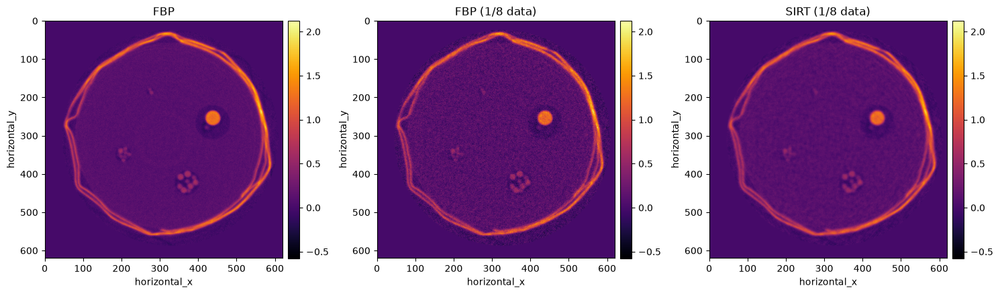

In [21]:
recon_sirt = sirt.solution
masked_recon_sirt = create_circular_mask(sirt.solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)

show2D([masked_fbp_full, masked_fbp_reduced, masked_recon_sirt], ['FBP', 'FBP (1/8 data)', 'SIRT (1/8 data)'], \
       cmap=cmap, num_cols=3, size=(15,10), origin='upper-left', fix_range=(range_min, range_max))

### Constrained reconstruction with SIRT
Perhaps the most intuitive constraint one can enforce on reconstructed data is the non-negativity constraint. The image data we are reconstructing is the linear attenuation coefficient of the material, so intuitively this cannot have a negative value. We enforce box constraints (lower and upper bounds) with the `IndicatorBox` function, which we can pass to SIRT with the 'constraint' parameter:

In [22]:
# initial estimate - zero array in this case 
initial = image_geometry.allocate(0)

constraint = IndicatorBox(lower=0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt_nn = SIRT(initial=initial, operator=A, data=reduced_data_slice, constraint=constraint)
sirt_nn.update_objective_interval = 1


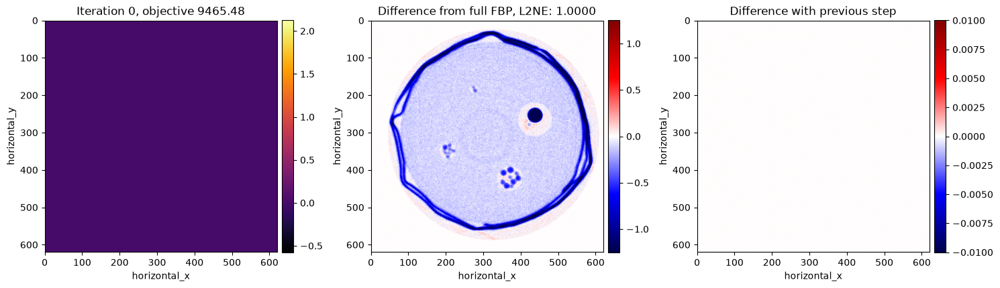

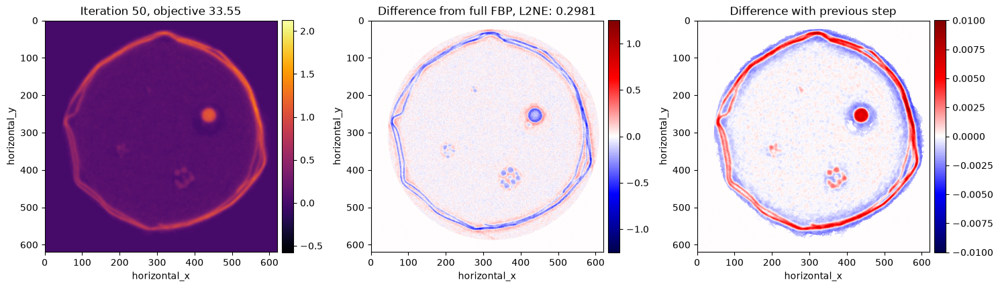

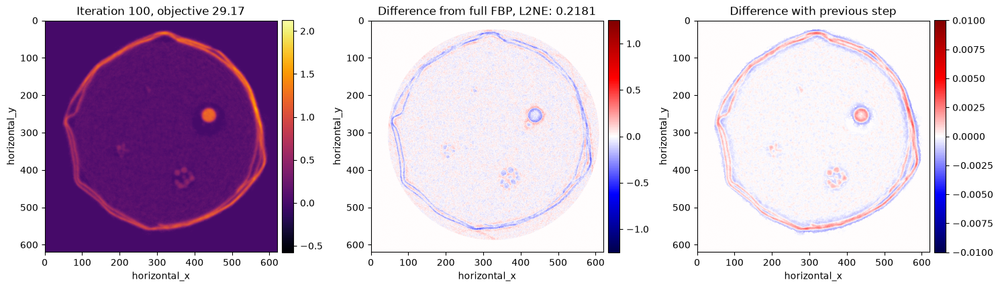

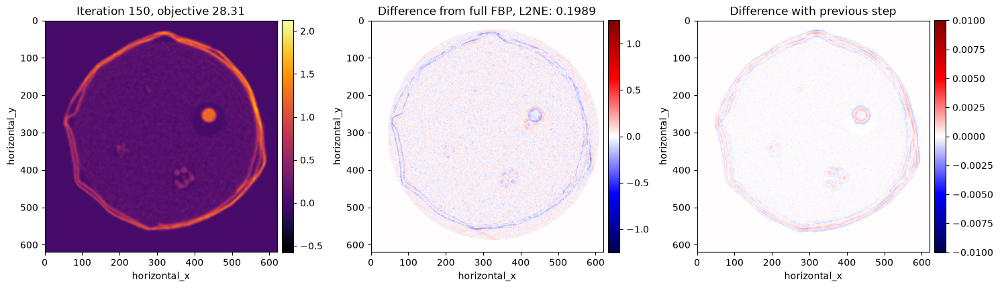

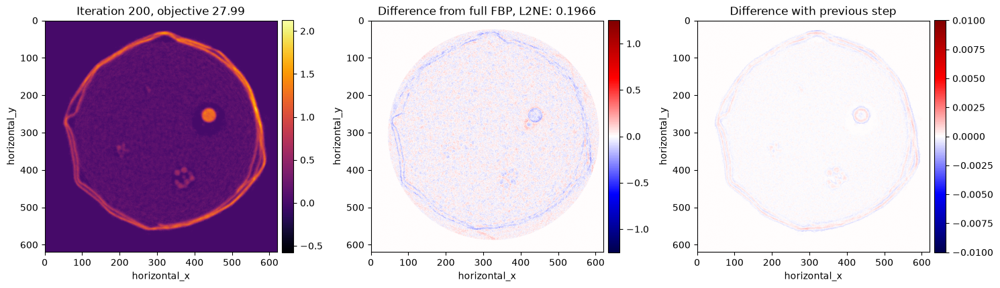

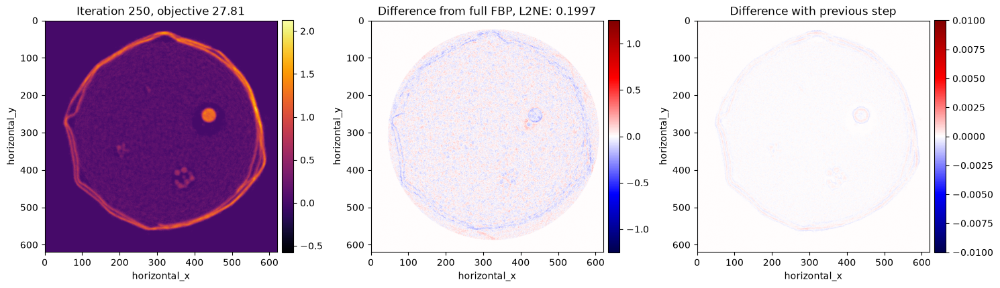

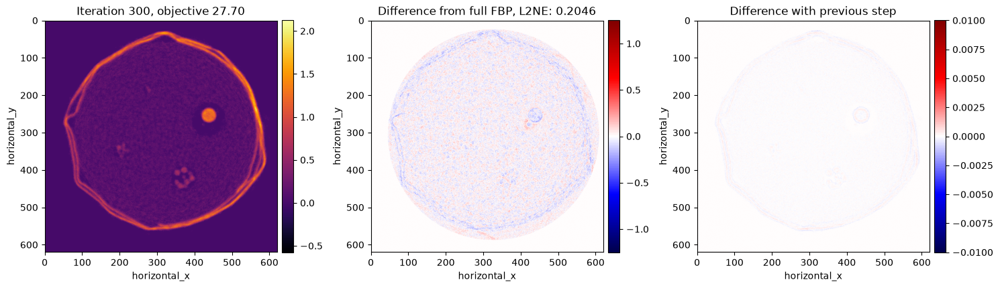

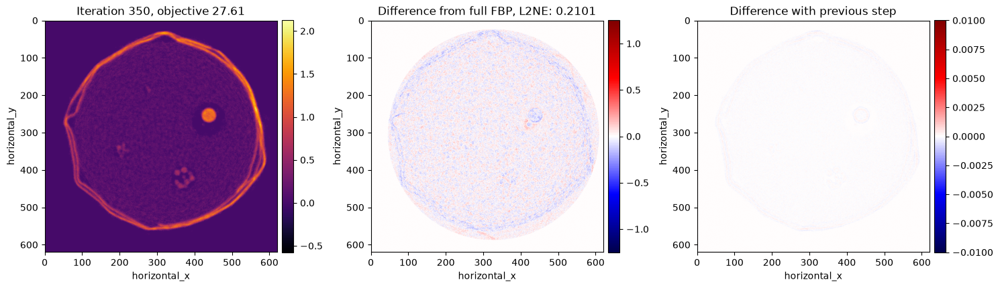

In [23]:
cb_nn = DifferenceImageCallback(target_image=masked_fbp_full, initial=initial, display_interval=50, fix_range=[(range_min, range_max), (-1.25, 1.25), (-0.01, 0.01)], cmap=[cmap, 'seismic', 'seismic'])
sirt_nn.run(350, callbacks=[cb_nn])

Again, we have seen that the solution gets closer to the FBP reconstruction, but after 200 iterations, the error gets larger, despite the objective value still getting smaller, as we can see in this plot as well:

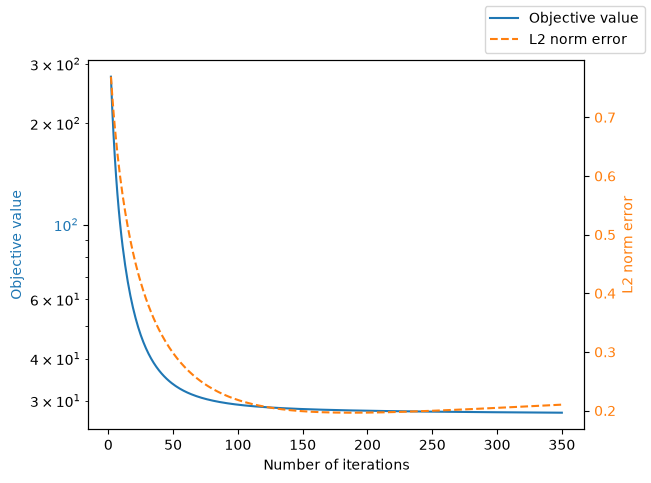

In [25]:
fig, ax1 = plt.subplots()

ax1.plot(sirt_nn.iterations[2:], sirt_nn.loss[2:], color='tab:blue')
ax1.set_yscale('log')
ax1.set_xlabel('Number of iterations')
ax1.set_ylabel('Objective value', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(sirt_nn.iterations[2:], cb_nn.l2nes[2:], '--', color='tab:orange') 
ax2.set_ylabel('L2 norm error', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
fig.legend(['Objective value', 'L2 norm error'])
plt.show()


In [26]:
iters = sirt_nn.iterations[cb_nn.l2nes.index(min(cb_nn.l2nes))]
print("The lowest L2 norm error is {:.4f} at iteration {}".format(min(cb_nn.l2nes), iters))
print("Now let's run with {} iterations".format(iters))

The lowest L2 norm error is 0.1964 at iteration 188
Now let's run with 188 iterations


In [27]:
initial = image_geometry.allocate(0)

constraint = IndicatorBox(lower=0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt_nn = SIRT(initial=initial, operator=A, data=reduced_data_slice, constraint=constraint)
sirt_nn.update_objective_interval = 10
sirt_nn.run(iters)

  0%|          | 0/188 [00:00<?, ?it/s]

### Comparison of SIRT with and without Non-negativity Constraint

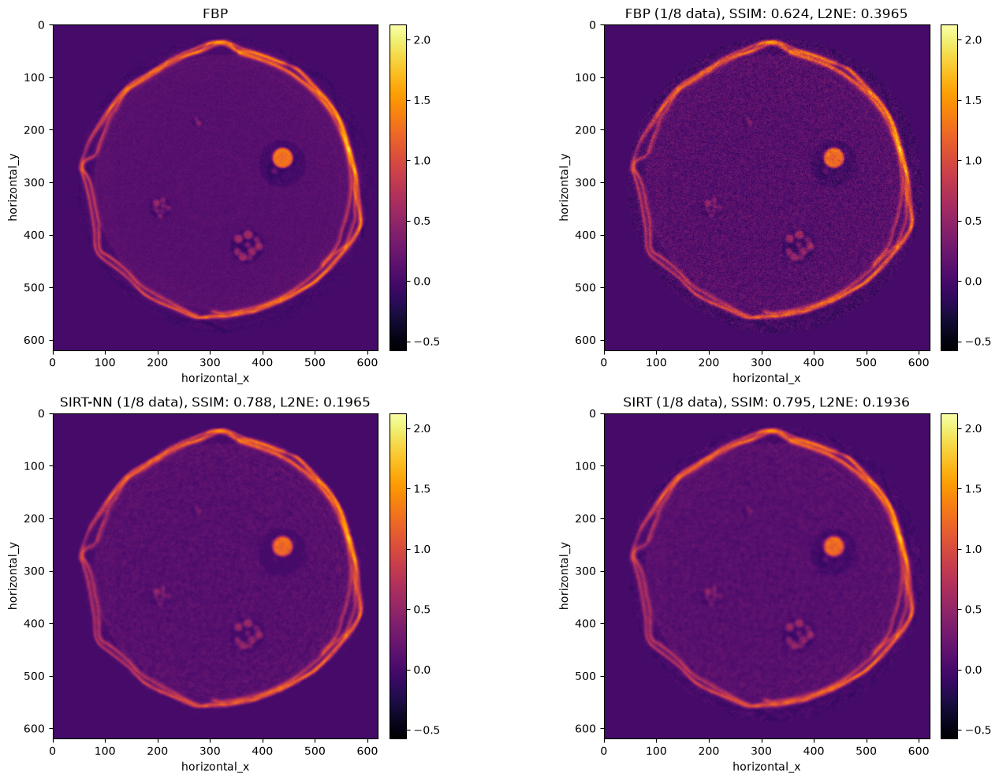

In [28]:
def title_with_metrics(name, reference, image):
    """Plot title with SSIM and L2NE of `image` compared to `reference` (both 2D ImageData)."""
    ref = reference.as_array()
    ssim_value = ssim(ref, image.as_array(), data_range=ref.max() - ref.min())
    l2_error = calculate_L2Norm_error(reference, image)
    return '{}, SSIM: {:.3f}, L2NE: {:.4f}'.format(name, ssim_value, l2_error)

recon_sirt_nn = sirt_nn.solution
recon_titles = ['FBP',
                'FBP (1/8 data)',
                'SIRT-NN (1/8 data)',
                'SIRT (1/8 data)']
# show2D([recon_fbp_full, recon_fbp_reduced, recon_sirt_nn, recon_sirt], recon_titles, \
#        cmap=cmap, num_cols=2, size=(15,10), origin='upper-left', fix_range=(range_min, range_max))

masked_sirt_nn = create_circular_mask(recon_sirt_nn, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
masked_sirt = create_circular_mask(recon_sirt, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)

masked_titles = ['FBP',
                 title_with_metrics('FBP (1/8 data)', masked_fbp_full, masked_fbp_reduced),
                 title_with_metrics('SIRT-NN (1/8 data)', masked_fbp_full, masked_sirt_nn),
                 title_with_metrics('SIRT (1/8 data)', masked_fbp_full, masked_sirt)]
show2D([masked_fbp_full, masked_fbp_reduced, masked_sirt_nn, masked_sirt], masked_titles, \
       cmap=cmap, num_cols=2, size=(15,10), origin='upper-left', fix_range=(range_min, range_max))

The SSIM is slightly higher (better) for unconstrained SIRT, plus the L2Norm Error is also lower (better).

However, remember these measures are limited as we are comparing to the full FBP, which is still noisy - its not a real ground truth.

We applied a circular mask to all of the reconstructions so that we are comparing what happens inside the sample, so the results are not skewed by the background. For all except SIRT with the non-negativity constraint we see a halo of noisy background just before the boundary of the circular mask, whereas with the non-negativity constraint the background is uniformly set to 0.

Let's have a look at some ROIs in the sample:

This first ROI shows a slice of a cylindrical hole containing a mixture of ZrO2 spheres (0.5mm diameter) and trisopheres (1mm diameter)

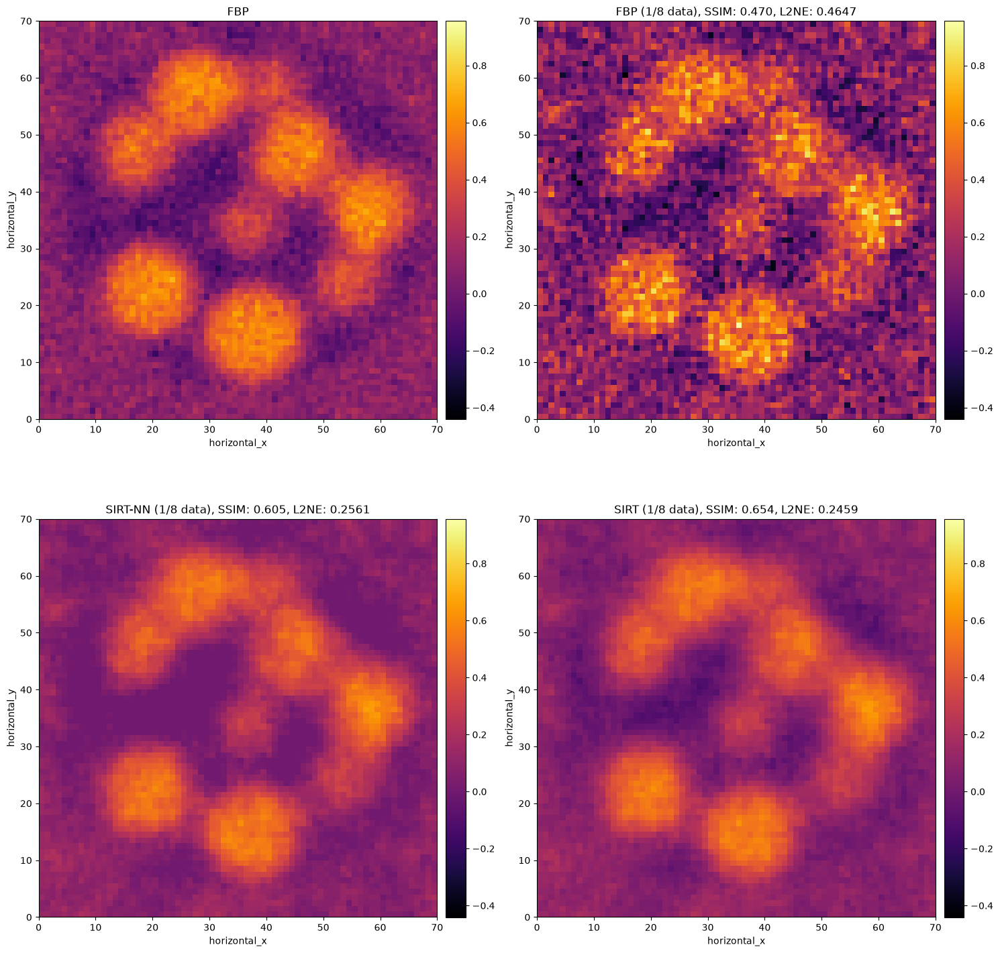

In [ ]:
multiple_beads_slicer = Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)})
rod_rois_full = multiple_beads_slicer(masked_fbp_full)
rod_rois_reduced = multiple_beads_slicer(masked_fbp_reduced)
rod_rois_sirt_nn = multiple_beads_slicer(masked_sirt_nn)
rod_rois_sirt = multiple_beads_slicer(masked_sirt)

show2D([x for x in [rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt]], fix_range=True, cmap=cmap, title=['FBP', title_with_metrics('FBP (1/8 data)', rod_rois_full, rod_rois_reduced), title_with_metrics('SIRT-NN (1/8 data)', rod_rois_full, rod_rois_sirt_nn), title_with_metrics('SIRT (1/8 data)', rod_rois_full, rod_rois_sirt)])

With the non-negativity constraint, we see less noise in the cylindrical hole the spheres sit inside.

In both SIRT reconstructions we see smoothing of noise within the spheres, and the aluminium cylinder itself.

In this second ROI we see a slice of a cylindrical hole which contains steel spheres (2mm diameter) in Aluminium foil.

We can see a large cut through of a sphere, but also the top of a second sphere is visible in the full FBP reconstruction, to the top left of the large sphere.

In [ ]:
large_and_small_slicer = Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})

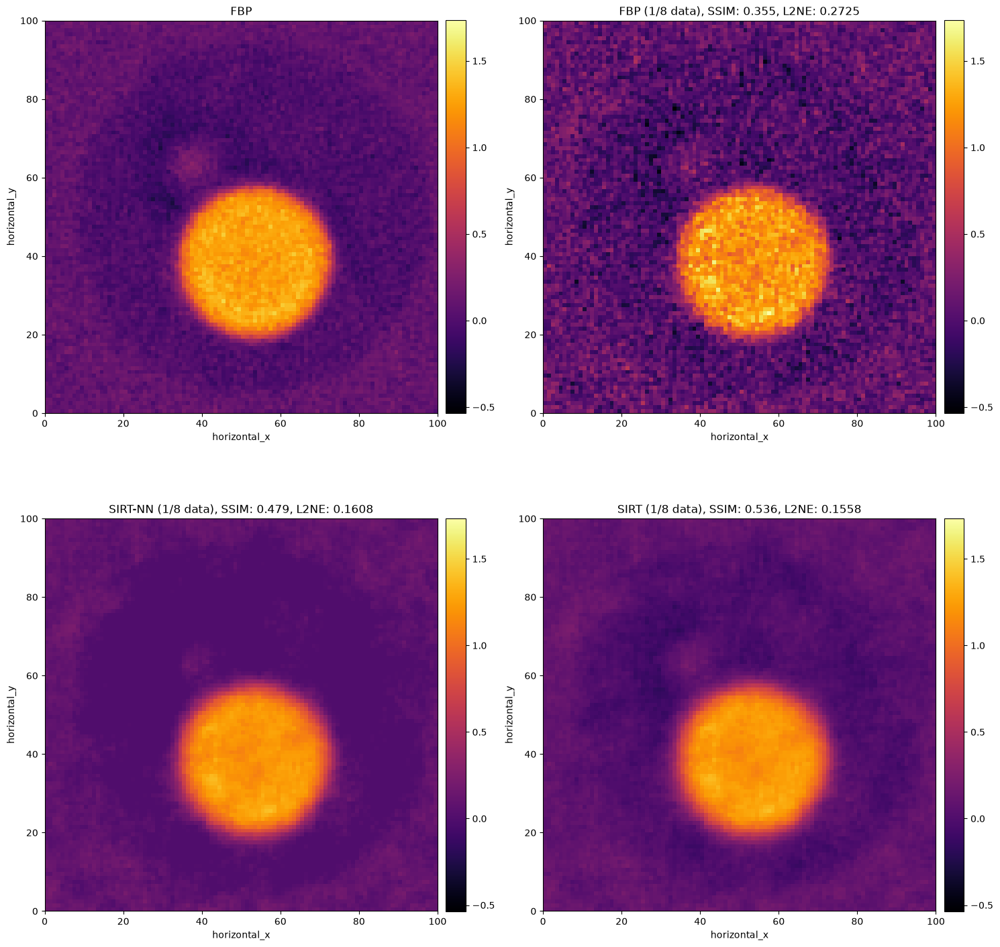

In [ ]:
rod_rois_full = large_and_small_slicer(masked_fbp_full)
rod_rois_reduced = large_and_small_slicer(masked_fbp_reduced)
rod_rois_sirt_nn = large_and_small_slicer(masked_sirt_nn)
rod_rois_sirt = large_and_small_slicer(masked_sirt)

show2D([rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt], fix_range=True, cmap=cmap, title=['FBP', title_with_metrics('FBP (1/8 data)', rod_rois_full, rod_rois_reduced), title_with_metrics('SIRT-NN (1/8 data)', rod_rois_full, rod_rois_sirt_nn), title_with_metrics('SIRT (1/8 data)', rod_rois_full, rod_rois_sirt)])

With the non-negativity constraint we see less noise in the hole that the spheres are located in but the small amount of sphere we see above the large sphere has been reduced in size when the non-negativity constraint is applied. However, it is easier to distinguish its presence compared to the background.

We can also look at line profiles through the reconstructions. This is a line profile through the larger diameter cut of a steel sphere:

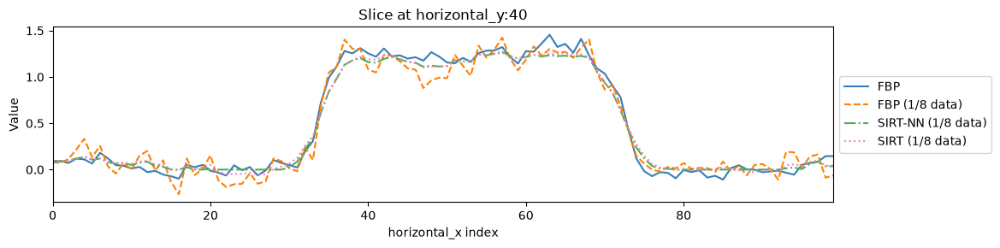

In [ ]:
show1D([rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt], slice_list=[('horizontal_y', 40)], dataset_labels=['FBP', 'FBP (1/8 data)', 'SIRT-NN (1/8 data)', 'SIRT (1/8 data)'], size=(12,3))

This line profile shows the smaller cut of sphere, between horizontal index ~30 and ~45. We see its more visible with the full FBP and SIRT than with SIRT with Non-negativity constraint. With the FBP on the reduced data, it can barely be seen in the noise in this line profile.

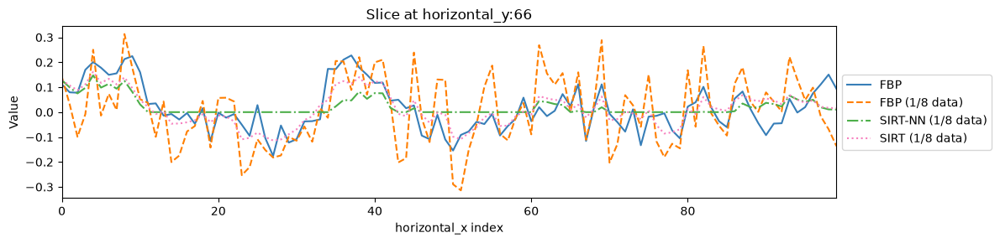

In [ ]:
show1D([rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt], slice_list=[('horizontal_y', 66)], dataset_labels=['FBP', 'FBP (1/8 data)', 'SIRT-NN (1/8 data)', 'SIRT (1/8 data)'], size=(12,3))

In this case, SIRT without the non-negativity constraint seems to be the better choice to avoid loss of information.

Depending on your sample and which features are of interest, it may be the case that SIRT could perform better with or without the non-negativity constraint.

Angles_vs_Exposure_03_SIRT.ipynb notebook shows SIRT and SIRT-NN applied to the full 3D dataset and looks at different metrics including signal to noise and contrast to noise across different slices of the sample.